# Strategic Form Audit
## tl;dr
El contraste externo recupera 5/5 puntos regulares. La enumeración de vértices externa falla en indiferencia total; no se confunde fallo con ausencia de equilibrio. Una tolerancia ex ante puede ocultar una desviación interina grande.

## Context & Methods
Dos prestamistas, estado y señales binarias, u_i=a_i(theta+alpha*a_j-c). Forma estratégica ex ante 4x4 calculada por suma de ocho estados. Nashpy 0.0.43 es externo; el poliedro racional existente es baseline.
### Key Assumptions
Señales condicionalmente independientes, prior interior, aleatorización independiente entre jugadores, sin datos reales ni identificación. La proyección conserva marginales por tipo, no correlaciones entre acciones contrafactuales.

In [1]:
import csv,json
from pathlib import Path
print(json.loads(Path('results/config.json').read_text())['regular'])
print(json.loads(Path('results/metadata.json').read_text()))

{'prior': 0.5, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}
{'seed': 20261016, 'python': '3.12.14', 'machine': 'x86_64', 'platform': 'Linux-6.18.44-x86_64-with-glibc2.39', 'cpu': 'x86_64', 'nashpy': '0.0.43', 'numpy': '2.3.5', 'source_commit': '681836e', 'memory': 'tracemalloc peak Python allocations, excludes native RSS', 'threshold': 1e-08, 'hashes': {'timing.csv': '550d3425ef78554083280ea3749d32d84e42bd626b5e624b2cbc2af1308a0525', 'equilibria.csv': '9384acdf229993c061ac302a38320dd470f9988f30ef22af50d6176320ff2037', 'rare_type_ablation.csv': '6c71c0858289706303f77a8217344751e99b56fabcf4416258fd91bb9dfca691', 'summary.csv': 'bd4c104f7d03f501953627d047cc038928899c5f968520fce7e9b401a4ce6b99', 'stability.csv': 'c9c4cf917cd4af697ad294e6c505873543160180d66e02b5d1979b1a8f2e3f86'}}


## Data
Payoffs sintéticos racionales exportados a .nfg. Orden de políticas: (0,0),(0,1),(1,0),(1,1); jugador uno varía más rápido. No se ejecutó Gambit; round-trip usa un parser limitado propio y Nashpy consume sus matrices.

In [2]:
print(Path('results/regular.nfg').read_text())

NFG 1 R "Bayesian credit freeze" { "Lender 0" "Lender 1" } { 4 4 }

0 0 -1/20 0 -7/20 0 -2/5 0 0 -1/20 111/500 111/500 -111/500 39/500 0 7/20 0 -7/20 39/500 -111/500 -39/500 -39/500 0 1/20 0 -2/5 7/20 0 1/20 0 2/5 2/5



## Results
La tabla cuenta vértices del baseline encontrados a tolerancia 1e-8; una lista finita no representa una familia continua completa.

In [3]:
for row in list(csv.DictReader(Path('results/summary.csv').open()))[:8]:
    print({k:row[k] for k in ['scenario','method','target_vertices','matched_vertices','max_interim_regret','status']})

{'scenario': 'regular', 'method': 'vertex_enumeration', 'target_vertices': '5', 'matched_vertices': '5', 'max_interim_regret': '3.6245516392174193e-16', 'status': 'ok'}
{'scenario': 'regular', 'method': 'support_enumeration', 'target_vertices': '5', 'matched_vertices': '5', 'max_interim_regret': '3.398017161766334e-17', 'status': 'ok'}
{'scenario': 'coordination_family', 'method': 'vertex_enumeration', 'target_vertices': '6', 'matched_vertices': '6', 'max_interim_regret': '0.0', 'status': 'ok'}
{'scenario': 'coordination_family', 'method': 'support_enumeration', 'target_vertices': '6', 'matched_vertices': '6', 'max_interim_regret': '0.0', 'status': 'ok'}
{'scenario': 'full_indifference', 'method': 'vertex_enumeration', 'target_vertices': '16', 'matched_vertices': '0', 'max_interim_regret': '', 'status': "TypeError: 'NoneType' object is not subscriptable"}
{'scenario': 'full_indifference', 'method': 'support_enumeration', 'target_vertices': '16', 'matched_vertices': '16', 'max_interim_r

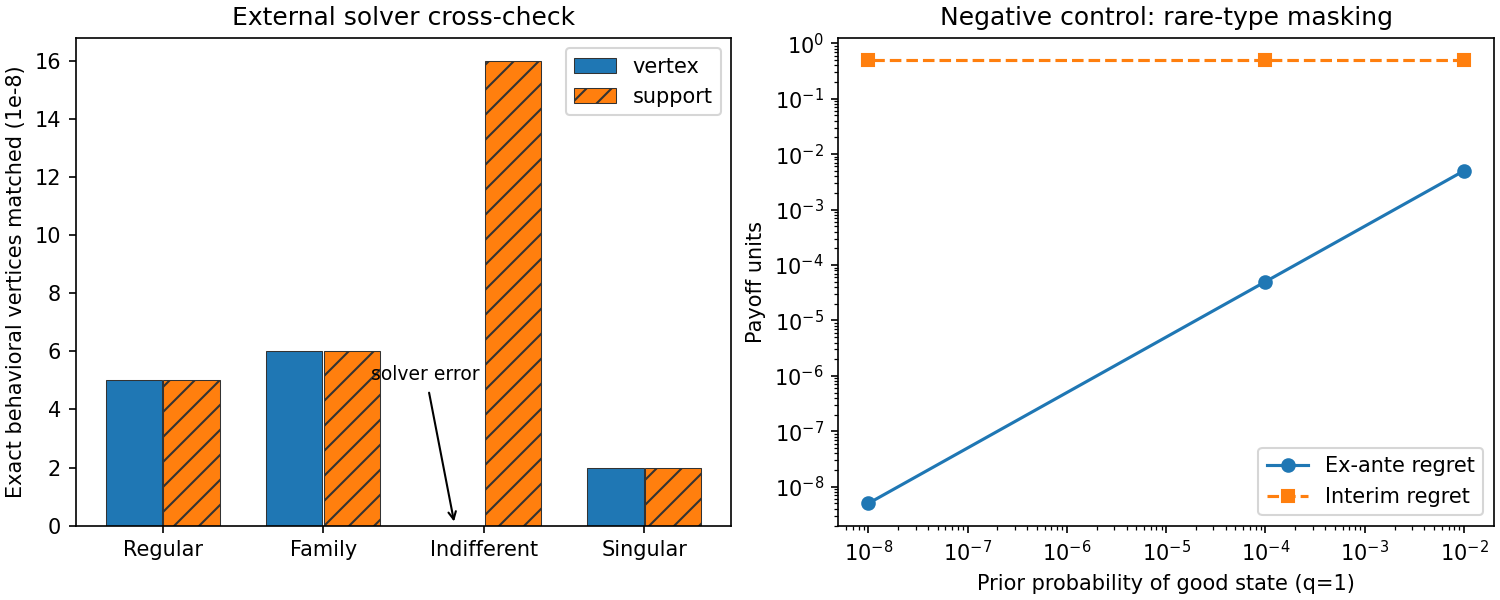

In [4]:
from IPython.display import Image,display
display(Image(filename='results/comparison.png'))

In [5]:
print(Path('results/rare_type_ablation.csv').read_text())
print(Path('results/coverage.txt').read_text())

prior,strategic_regret,interim_regret
0.01,0.005,0.5
0.0001,5e-05,0.5
1e-08,5e-09,0.5

Name               Stmts   Miss Branch BrPart  Cover   Missing
--------------------------------------------------------------
src/strategic.py      55      0     14      0   100%
--------------------------------------------------------------
TOTAL                 55      0     14      0   100%



## Takeaways
Validar regret condicional por tipo y conservar familias poliédricas: menor regret ex ante no certifica por sí solo un equilibrio interino aproximado uniforme. Cobertura medida sólo de src/ nuevo; pruebas no equivalen a demostración de completitud. Ver informe.md y referencias.bib para límites y literatura.

## Desarrollo experimental ampliado — 18 de octubre de 2026

Las siguientes celdas recalculan nuevos experimentos desde los modelos e inputs. Los resultados históricos anteriores se conservan como evidencia separada. Cada experimento declara su alcance; no eleva automáticamente la madurez del proyecto.

### 1. Regret ex ante y protección de tipos raros
Si $r_t$ es la ganancia por desviarse condicional al tipo y $\pi_t$ su probabilidad, el regret ex ante satisface $R=\sum_t\pi_t r_t$ cuando las acciones contingentes se eligen libremente. Por tanto $r_t\leq R/\pi_t$, pero una tolerancia global fija no da una garantía uniforme cuando $\pi_t\to0$. Se construye un caso con un único tipo que puede mejorar en 0.2; no se estima una frecuencia empírica.

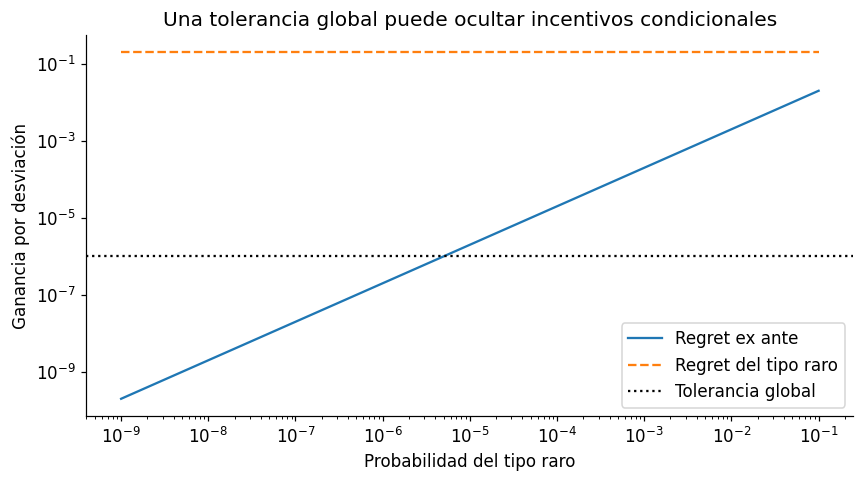

Frontera analítica de aceptación: 4.9999999999999996e-06


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
tolerance=1e-6
rare_probability=np.geomspace(1e-9,.1,81)
conditional_gain=.2
rare_table=pd.DataFrame({'probability':rare_probability,'interim_regret':conditional_gain,
    'exante_regret':rare_probability*conditional_gain})
rare_table['accepted_exante']=rare_table.exante_regret<=tolerance
rare_table['implied_uniform_bound']=tolerance/rare_table.probability
assert rare_table.accepted_exante.any()
assert (rare_table.loc[rare_table.accepted_exante,'interim_regret']>tolerance).all()
fig,ax=plt.subplots()
ax.loglog(rare_probability,rare_table.exante_regret,label='Regret ex ante')
ax.loglog(rare_probability,rare_table.interim_regret,'--',label='Regret del tipo raro')
ax.axhline(tolerance,color='black',linestyle=':',label='Tolerancia global')
ax.set(xlabel='Probabilidad del tipo raro',ylabel='Ganancia por desviación',title='Una tolerancia global puede ocultar incentivos condicionales')
ax.legend();plt.show()
print('Frontera analítica de aceptación:',tolerance/conditional_gain)

### 2. Recalcular la forma estratégica y una propiedad de invariancia
La suma sobre estados latentes del código del proyecto permite recalcular matrices 4×4. Cambiar el acoplamiento de políticas de un mismo jugador, conservando marginales, debe conservar el pago esperado bajo la estructura de información especificada.

In [7]:
from src.strategic import Game,matrices,project,lift,strategic_regret
A,B=matrices(Game())
A_float,B_float=np.array(A,float),np.array(B,float)
p1=np.array([.5,0,0,.5]); p2=np.array([0,.5,.5,0]); other=lift(np.array([.2,.8]))
assert np.allclose(project(p1),project(p2))
assert abs(p1@A_float@other-p2@A_float@other)<1e-12
display(pd.DataFrame(A_float,index=['00','01','10','11'],columns=['00','01','10','11']))
print('Pago con mezcla A:',p1@A_float@other,'; con mezcla B:',p2@A_float@other)
assert strategic_regret(A,B,lift(np.zeros(2)),lift(np.zeros(2)))==0

Pago con mezcla A: 1.4266365866433262e-17 ; con mezcla B: 9.825473767932635e-18


,00,01,10,11
00,0.00,0.000,0.000,0.00
01,-0.05,0.222,0.078,0.35
10,-0.35,-0.222,-0.078,0.05
11,-0.40,0.000,0.000,0.40


### 3. Separar ausencia de solución de fallo del solver
Los estados de ejecución se muestran junto a la recuperación de vértices. La tasa de recuperación se deja indefinida ante fallo: no se convierte una excepción numérica en evidencia económica de ausencia de equilibrio.

In [8]:
saved=pd.read_csv('results/summary.csv')
saved['vertex_recovery']=np.where(saved.status.eq('ok') & saved.target_vertices.gt(0),
    saved.matched_vertices/saved.target_vertices,np.nan)
display(saved[['scenario','method','target_vertices','matched_vertices','vertex_recovery','status']])
assert saved.loc[~saved.status.eq('ok'),'vertex_recovery'].isna().all()
print('Filas con fallo explícito:',int((~saved.status.eq('ok')).sum()))

Filas con fallo explícito: 1


,scenario,method,target_vertices,matched_vertices,vertex_recovery,status
0,regular,vertex_enumeration,5,5,1.0,ok
1,regular,support_enumeration,5,5,1.0,ok
2,coordination_family,vertex_enumeration,6,6,1.0,ok
3,coordination_family,support_enumeration,6,6,1.0,ok
4,full_indifference,vertex_enumeration,16,0,NaN,TypeError: 'NoneType' object is not subscriptable
5,full_indifference,support_enumeration,16,16,1.0,ok
6,singular_isolated,vertex_enumeration,2,2,1.0,ok
7,singular_isolated,support_enumeration,2,2,1.0,ok
8,random_0,vertex_enumeration,5,5,1.0,ok
9,random_0,support_enumeration,5,5,1.0,ok


### 4. Implicación para validación
Una política de aceptación debe declarar si protege al jugador promedio o a cada tipo. Cuando se exige garantía por tipo, hay que medir regret interino directamente o adaptar tolerancias a probabilidades positivas conocidas. El ejemplo no establece una calibración estadística ni una política de crédito; identifica una fragilidad lógica del criterio agregado.

### Lectura de los resultados ejecutados

Con ganancia condicional **0.2** y tolerancia ex ante **10⁻⁶**, el criterio agregado acepta el ejemplo cuando la probabilidad del tipo es como máximo **5×10⁻⁶**. El corpus guardado contiene **una fila con fallo explícito**, conservada como recuperación indefinida. Los pagos de las dos mezclas equivalentes difieren únicamente al nivel de redondeo flotante.